<a href="https://colab.research.google.com/github/pastelpaint/pastel-paint/blob/main/ml4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

step 0

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn. model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn. linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn. tree import DecisionTreeClassifier, plot_tree
from sklearn. metrics import accuracy_score, precision_score, recall_score,f1_score, confusion_matrix, ConfusionMatrixDisplay

Srep 1

In [11]:
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'
column_names = ['Pregnancies','Glucose','BloodPressure', 'SkinThickness',
'Insulin','BMI','DiabetesPedigreeFunction','Age','Outcome']
df = pd. read_csv(url, names=column_names)
print("Data Shape: ", df. shape)
print ("Dataset Structure:")
display(df.head ())
print ("\nSummary Statistics:")
display(df.describe())

Data Shape:  (768, 9)
Dataset Structure:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Summary Statistics:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Step 2

In [14]:
cols_to_fix = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols_to_fix] = df[cols_to_fix]. replace(0, np.nan)
df.fillna(df. median(), inplace=True)
print("Missing values after imputation:")
print(df.isnull(). sum())

Missing values after imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


Step 3

/tmp/ipykernel_1983/1769001387.py:2: UserWarning: To output multiple subplots, the figure containing the passed axes is being cleared.
  df.hist(ax=plt.gca())


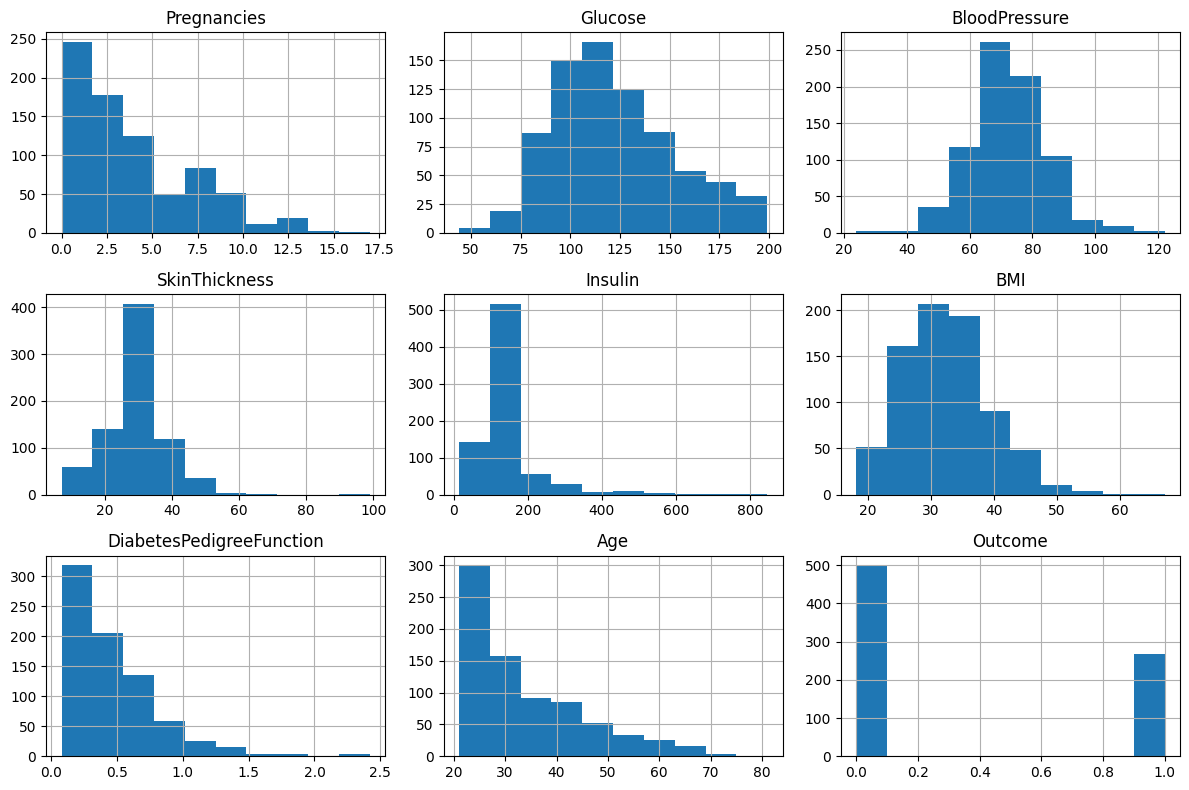

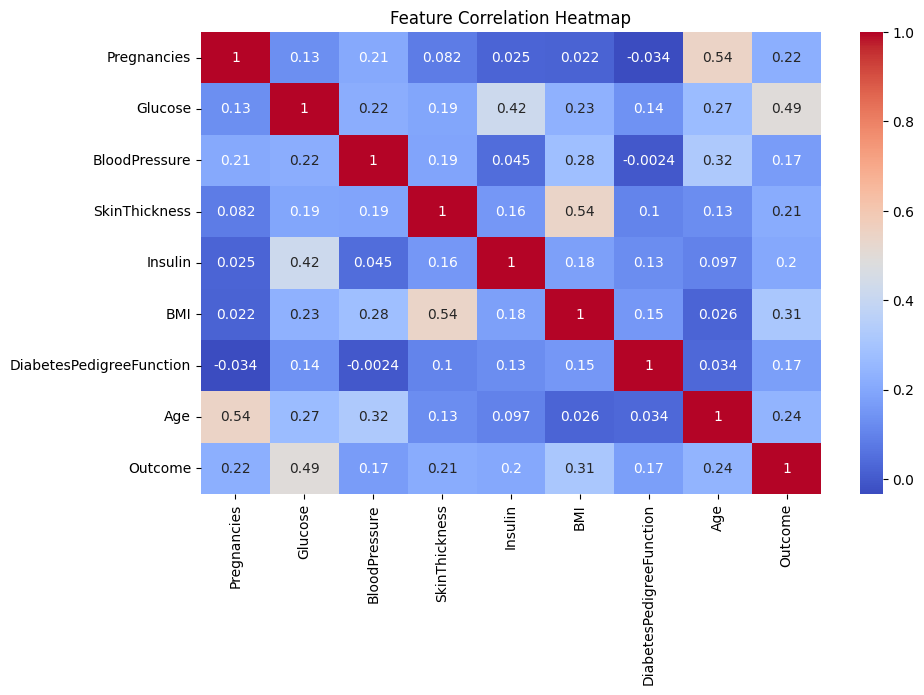

In [15]:
plt. figure(figsize=(12, 8))
df.hist(ax=plt.gca())
plt. tight_layout()
plt. show()
plt. figure(figsize=(10,6))
sns. heatmap(df.corr(), annot=True, cmap='coolwarm')
plt. title("Feature Correlation Heatmap")
plt. show()

Step 4&5

In [17]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Step 6

In [19]:
def evaluate_model(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred)}
lr = LogisticRegression()
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)
lr_results = evaluate_model(y_test, y_pred_lr)

Step 7

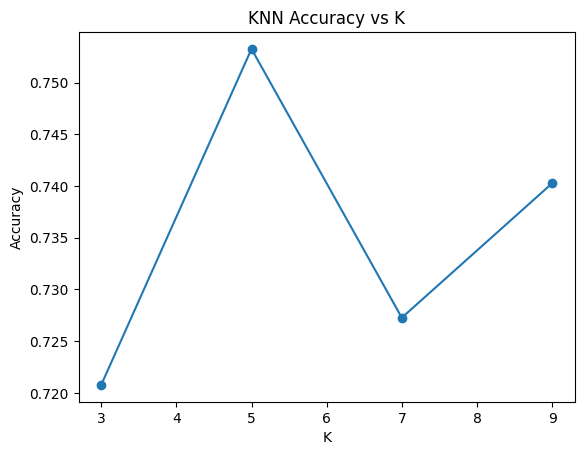

In [25]:
ks = [3, 5, 7, 9]
knn_accs = []
for k in ks:
 knn = KNeighborsClassifier(n_neighbors=k)
 knn.fit(X_train_scaled, y_train)
 knn_accs.append(accuracy_score(y_test, knn.predict(X_test_scaled)))
plt.plot(ks, knn_accs, marker='o')
plt.title("KNN Accuracy vs K")
plt.xlabel("K")
plt.ylabel("Accuracy")
plt.show()
best_knn = KNeighborsClassifier(n_neighbors=9)
best_knn.fit(X_train_scaled, y_train)
y_pred_knn = best_knn.predict(X_test_scaled)
knn_results = evaluate_model(y_test, y_pred_knn)

Step 8

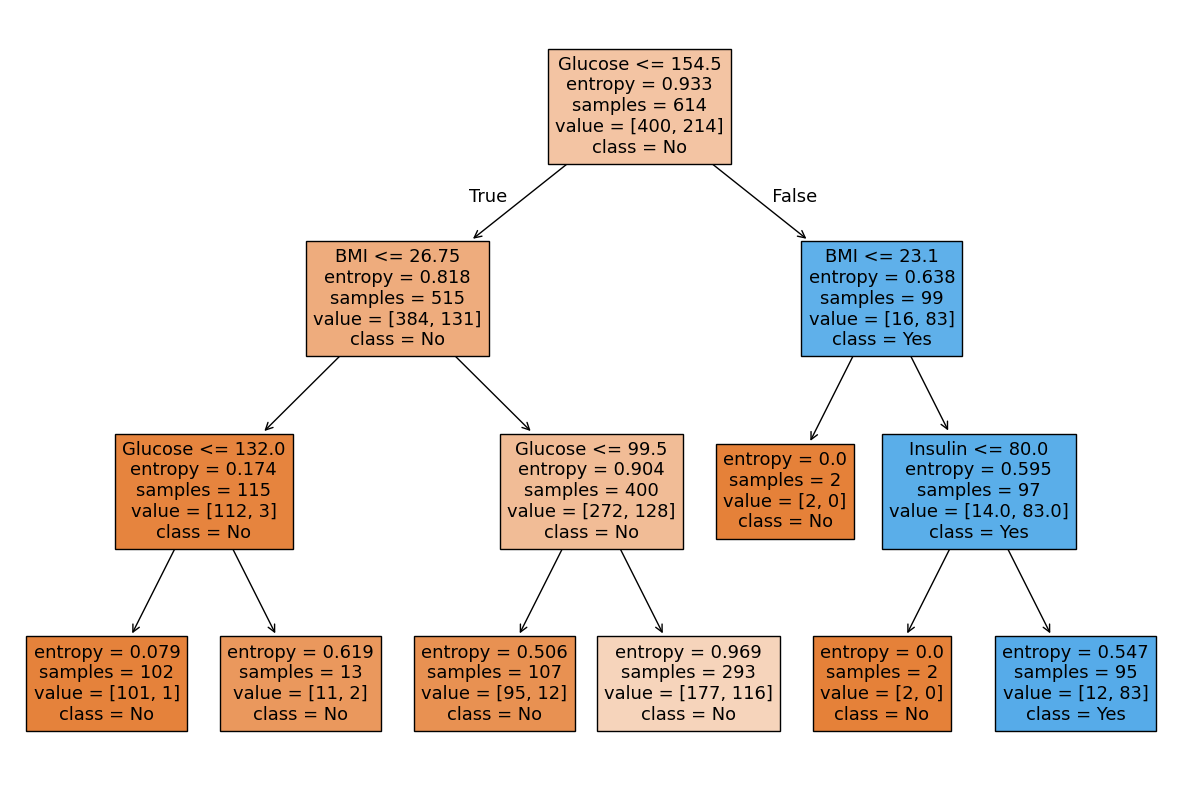

In [21]:
dt = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
dt_results = evaluate_model(y_test, y_pred_dt)
plt.figure(figsize=(15, 10))
plot_tree(dt, feature_names=X.columns, class_names=['No', 'Yes'], filled=True)
plt.show()

Step 9

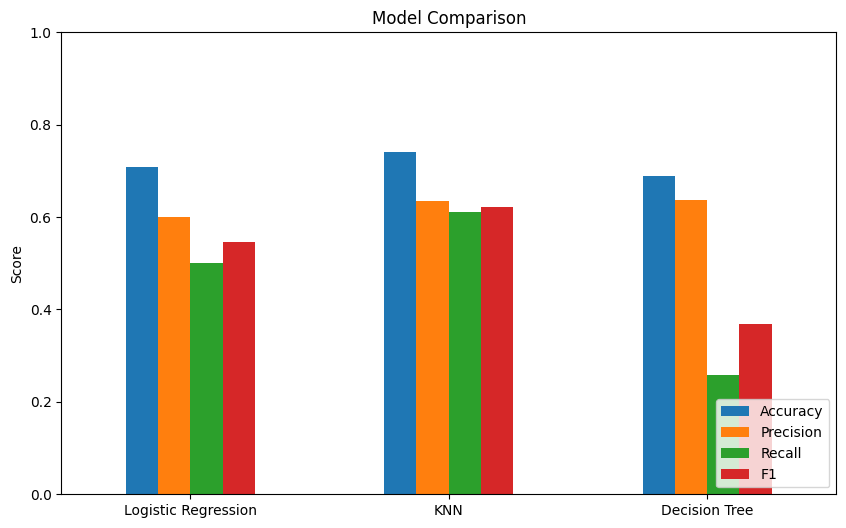

In [22]:
results_df = pd.DataFrame([lr_results, knn_results, dt_results], index=['Logistic Regression', 'KNN', 'Decision Tree'])
results_df.plot(kind='bar', figsize=(10, 6))
plt.title("Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.0)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

Step 10

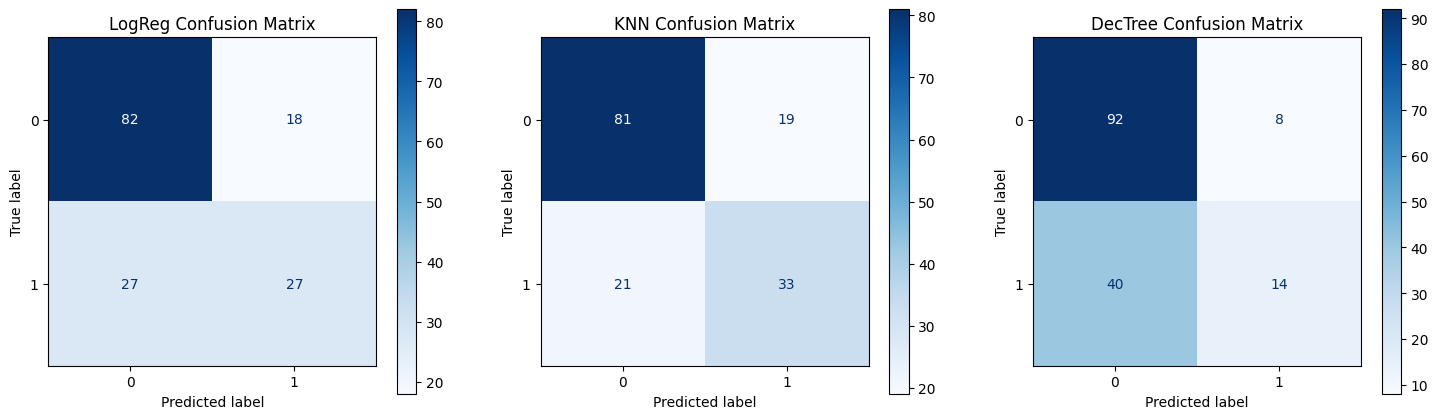

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
models = [('LogReg', y_pred_lr), ('KNN', y_pred_knn), ('DecTree', y_pred_dt)]
for i, (name, pred) in enumerate(models):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm).plot(ax=axes[i], cmap='Blues')
    axes[i].set_title(f'{name} Confusion Matrix')
plt.show()